In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from src.treinar_pipeline_churn import obter_dataset

df = obter_dataset()
print(f"Total de registros: {len(df)}")
display(df.head(10))

Carregando dataset do Kaggle: WA_Fn-UseC_-Telco-Customer-Churn.csv
Total de registros: 7043


,tempo_cliente_meses,valor_mensal,tipo_contrato,forma_pagamento,churn
0,1,29.85,mensal,boleto,0
1,34,56.95,anual,boleto,0
2,2,53.85,mensal,boleto,1
3,45,42.30,anual,pix,0
4,2,70.70,mensal,boleto,1
5,8,99.65,mensal,boleto,1
6,22,89.10,mensal,cartao,0
7,10,29.75,mensal,boleto,0
8,28,104.80,mensal,boleto,1
9,62,56.15,anual,pix,0


In [2]:
print("=== Média por Classe (0 = Ativo | 1 = Cancelou) ===")
display(df.groupby("churn")[["tempo_cliente_meses", "valor_mensal"]].mean().round(2))

print("\n=== Exemplos Reais de Clientes que Cancelaram (churn = 1) ===")
display(df[df["churn"] == 1].head(5))

print("\n=== Exemplos Reais de Clientes Fiéis (churn = 0) ===")
display(df[df["churn"] == 0].head(5))

=== Média por Classe (0 = Ativo | 1 = Cancelou) ===


,tempo_cliente_meses,valor_mensal
churn,,
0,37.57,61.27
1,17.98,74.44



=== Exemplos Reais de Clientes que Cancelaram (churn = 1) ===


,tempo_cliente_meses,valor_mensal,tipo_contrato,forma_pagamento,churn
2,2,53.85,mensal,boleto,1
4,2,70.70,mensal,boleto,1
5,8,99.65,mensal,boleto,1
8,28,104.80,mensal,boleto,1
13,49,103.70,mensal,pix,1



=== Exemplos Reais de Clientes Fiéis (churn = 0) ===


,tempo_cliente_meses,valor_mensal,tipo_contrato,forma_pagamento,churn
0,1,29.85,mensal,boleto,0
1,34,56.95,anual,boleto,0
3,45,42.30,anual,pix,0
6,22,89.10,mensal,cartao,0
7,10,29.75,mensal,boleto,0


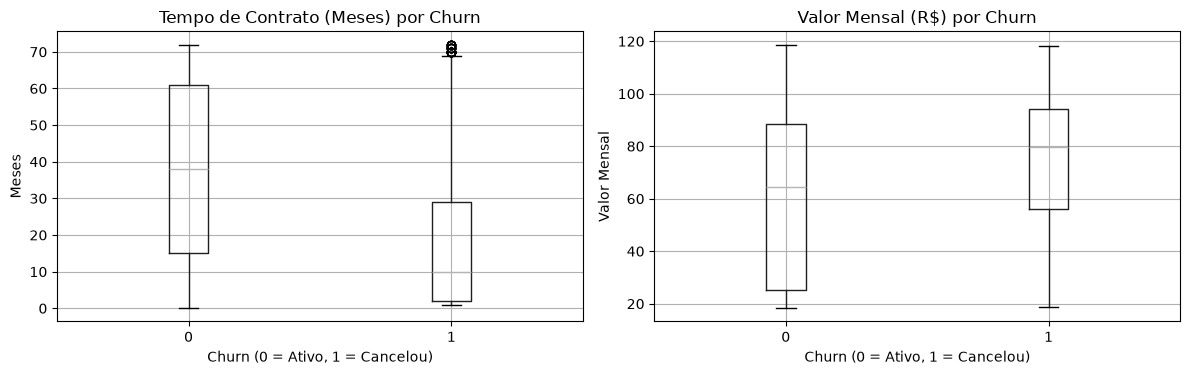

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Gráfico 1: Tempo de contrato por classe
df.boxplot(column="tempo_cliente_meses", by="churn", ax=axes[0])
axes[0].set_title("Tempo de Contrato (Meses) por Churn")
axes[0].set_xlabel("Churn (0 = Ativo, 1 = Cancelou)")
axes[0].set_ylabel("Meses")

# Gráfico 2: Valor mensal por classe
df.boxplot(column="valor_mensal", by="churn", ax=axes[1])
axes[1].set_title("Valor Mensal (R$) por Churn")
axes[1].set_xlabel("Churn (0 = Ativo, 1 = Cancelou)")
axes[1].set_ylabel("Valor Mensal")

plt.suptitle("")
plt.tight_layout()
plt.show()

In [4]:
amostra_cancelou = df[df["churn"] == 1].iloc[1].drop("churn").to_dict()
amostra_ativo = df[df["churn"] == 0].iloc[1].drop("churn").to_dict()

print("Payload de teste (Cliente Real que Cancelou - Esperado: 1):")
print(json.dumps(amostra_cancelou, indent=2, ensure_ascii=False))

print("\nPayload de teste (Cliente Real Ativo - Esperado: 0):")
print(json.dumps(amostra_ativo, indent=2, ensure_ascii=False))

Payload de teste (Cliente Real que Cancelou - Esperado: 1):
{
  "tempo_cliente_meses": 2,
  "valor_mensal": 70.7,
  "tipo_contrato": "mensal",
  "forma_pagamento": "boleto"
}

Payload de teste (Cliente Real Ativo - Esperado: 0):
{
  "tempo_cliente_meses": 34,
  "valor_mensal": 56.95,
  "tipo_contrato": "anual",
  "forma_pagamento": "boleto"
}
